# Student Performance Prediction

**Team:** Tanmay Raghav, Aditya Sirohi, Ritivik Sharma  
**Submitted to:** Professor Nirbhay, GLA University

This notebook compares prediction with G1/G2 available and prediction without them. It includes a mean baseline, five-fold cross-validation, Random Forest tuning, residual plots, feature importance and a sensitivity check for G3 = 0. Earlier grades are valid inputs when they are available at prediction time; excluding them is a different task.

Run all cells to execute the workflow.


Dataset shape: (395, 33)
Missing values: 0

G3 = 0 records: 38
count    38.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0
Name: absences, dtype: float64
The dataset does not explain why these grades are zero.


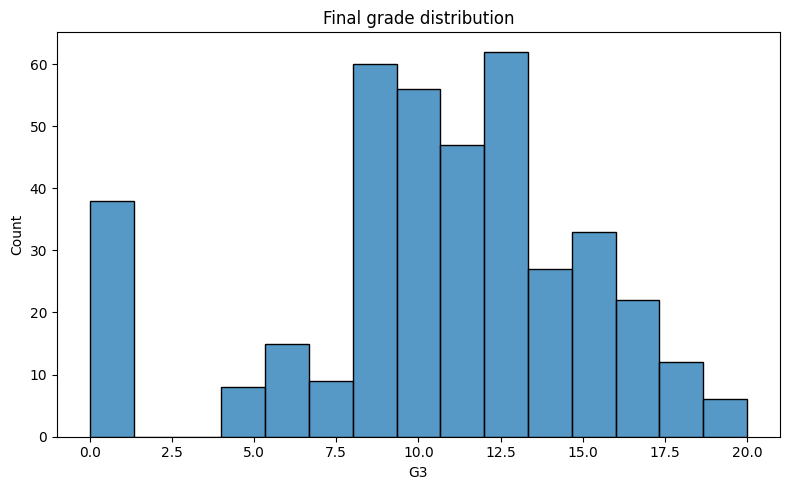

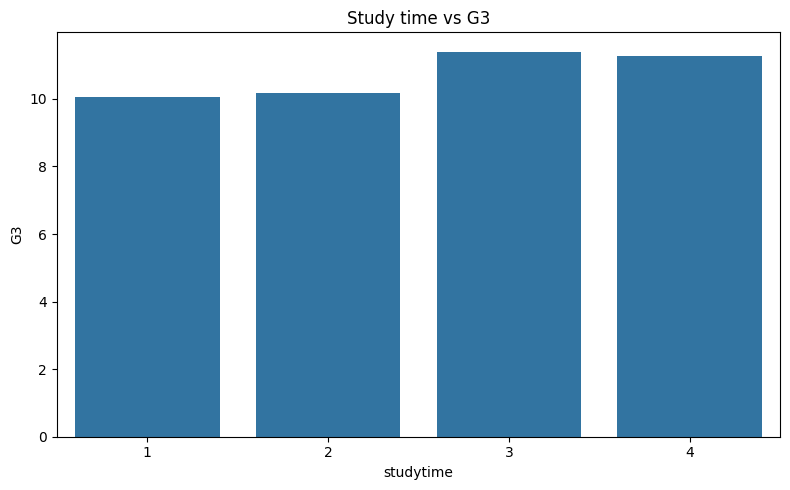

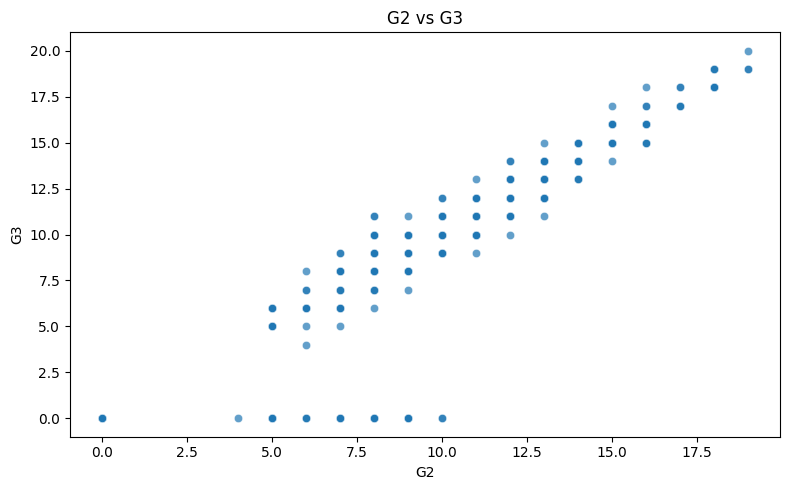


With G1/G2 (earlier grades available)
Best parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}


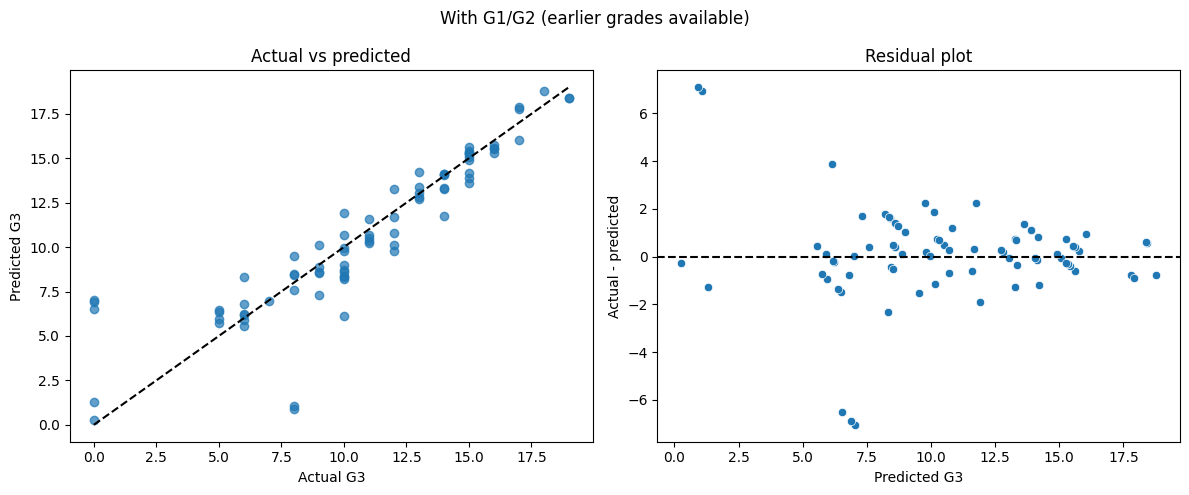

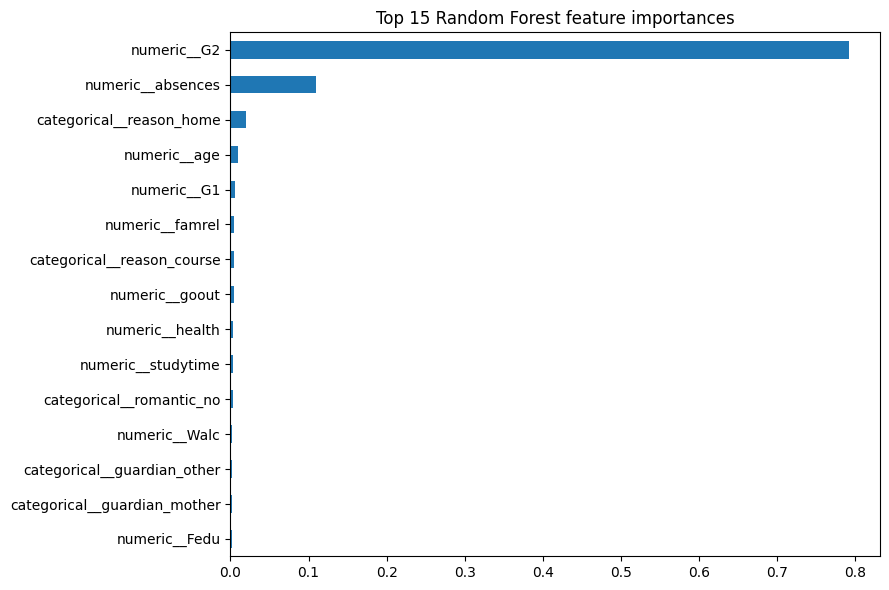

Metrics on positive-grade test records: {'MAE': 0.9784692231790697, 'MSE': 2.4397669093721484, 'RMSE': np.float64(1.561975322907551), 'R2': 0.8195474749689765}

Without G1/G2 (earlier grades unavailable)
Best parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}


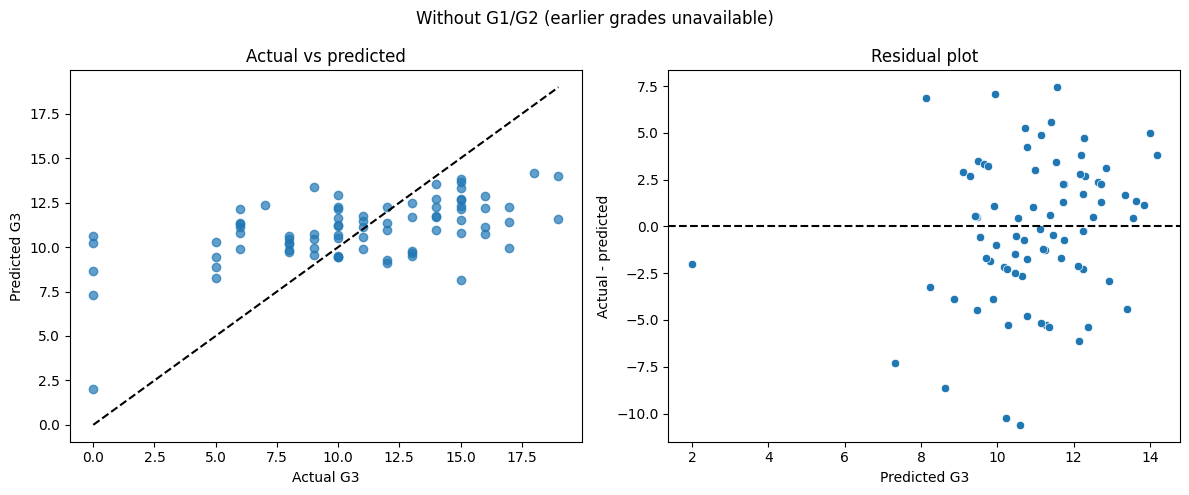

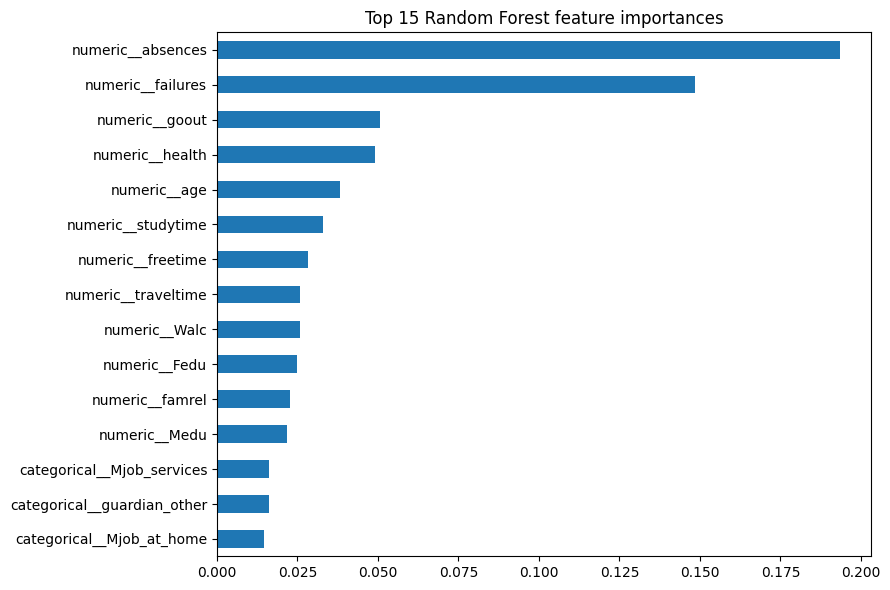

Metrics on positive-grade test records: {'MAE': 2.733883795919905, 'MSE': 10.87730010089202, 'RMSE': np.float64(3.298075211527478), 'R2': 0.1954820515082364}

Five-fold cross-validation results:
                                Experiment                   Model  CV RMSE mean  CV RMSE std
     With G1/G2 (earlier grades available)           Mean baseline         4.575        0.372
     With G1/G2 (earlier grades available)       Linear Regression         1.895        0.209
     With G1/G2 (earlier grades available) Random Forest (default)         1.420        0.253
     With G1/G2 (earlier grades available)   Random Forest (tuned)         1.386          NaN
Without G1/G2 (earlier grades unavailable)           Mean baseline         4.575        0.372
Without G1/G2 (earlier grades unavailable)       Linear Regression         4.699        0.217
Without G1/G2 (earlier grades unavailable) Random Forest (default)         3.878        0.277
Without G1/G2 (earlier grades unavailable)   Random F

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Load dataset: use the local CSV if uploaded, otherwise download it from GitHub.
DATA_PATH = Path("student-mat.csv")
if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH, sep=";")
else:
    df = pd.read_csv(
        "https://raw.githubusercontent.com/Tanmayraghav/DATA-SCIENCE-/main/03_Dataset/student-mat.csv",
        sep=";"
    )

df = df.drop_duplicates().copy()
print("Dataset shape:", df.shape)
print("Missing values:", int(df.isnull().sum().sum()))

# Basic dataset analysis
zeros = df[df["G3"] == 0]
print("\nG3 = 0 records:", len(zeros))
print(zeros["absences"].describe())
print("The dataset does not explain why these grades are zero.")

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="G3", bins=15)
plt.title("Final grade distribution")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="studytime", y="G3", errorbar=None)
plt.title("Study time vs G3")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="G2", y="G3", alpha=0.7)
plt.title("G2 vs G3")
plt.tight_layout()
plt.show()


def build_model(X, model, scale=False):
    numeric_columns = X.select_dtypes(include=np.number).columns.tolist()
    categorical_columns = X.select_dtypes(exclude=np.number).columns.tolist()

    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scaler", StandardScaler()))

    preprocessing = ColumnTransformer([
        ("numeric", Pipeline(numeric_steps), numeric_columns),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_columns)
    ])

    return Pipeline([
        ("preprocessor", preprocessing),
        ("model", model)
    ])


def get_metrics(actual, predicted):
    mse = mean_squared_error(actual, predicted)
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(actual, predicted)
    }


# Keep one fixed train/test split for fair comparison.
y = df["G3"]
X = df.drop(columns=["G3"])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

experiments = {
    "With G1/G2 (earlier grades available)": (X_train, X_test),
    "Without G1/G2 (earlier grades unavailable)": (
        X_train.drop(columns=["G1", "G2"]),
        X_test.drop(columns=["G1", "G2"])
    )
}

test_rows = []
cv_rows = []

for label, (X_train_exp, X_test_exp) in experiments.items():
    print("\n" + "=" * 65)
    print(label)

    models = {
        "Mean baseline": build_model(
            X_train_exp, DummyRegressor(strategy="mean")
        ),
        "Linear Regression": build_model(
            X_train_exp, LinearRegression(), scale=True
        ),
        "Random Forest (default)": build_model(
            X_train_exp,
            RandomForestRegressor(
                n_estimators=200, random_state=42, n_jobs=-1
            )
        )
    }

    for model_name, model in models.items():
        scores = -cross_val_score(
            model, X_train_exp, y_train,
            cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1
        )
        cv_rows.append({
            "Experiment": label,
            "Model": model_name,
            "CV RMSE mean": scores.mean(),
            "CV RMSE std": scores.std()
        })

        model.fit(X_train_exp, y_train)
        predictions = model.predict(X_test_exp)
        test_rows.append({
            "Experiment": label,
            "Model": model_name,
            **get_metrics(y_test, predictions)
        })

    # Tune Random Forest using training data only.
    random_forest = build_model(
        X_train_exp,
        RandomForestRegressor(random_state=42, n_jobs=-1)
    )
    parameter_grid = {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_leaf": [1, 2]
    }

    search = GridSearchCV(
        random_forest,
        parameter_grid,
        cv=5,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )
    search.fit(X_train_exp, y_train)

    best_model = search.best_estimator_
    predictions = best_model.predict(X_test_exp)

    test_rows.append({
        "Experiment": label,
        "Model": "Random Forest (tuned)",
        **get_metrics(y_test, predictions)
    })
    cv_rows.append({
        "Experiment": label,
        "Model": "Random Forest (tuned)",
        "CV RMSE mean": -search.best_score_,
        "CV RMSE std": np.nan
    })

    print("Best parameters:", search.best_params_)

    # Actual vs predicted and residual plots.
    residuals = y_test - predictions
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].scatter(y_test, predictions, alpha=0.7)
    lower = min(float(y_test.min()), float(predictions.min()))
    upper = max(float(y_test.max()), float(predictions.max()))
    axes[0].plot([lower, upper], [lower, upper], "k--")
    axes[0].set(
        title="Actual vs predicted",
        xlabel="Actual G3",
        ylabel="Predicted G3"
    )

    sns.scatterplot(x=predictions, y=residuals, ax=axes[1])
    axes[1].axhline(0, color="black", linestyle="--")
    axes[1].set(
        title="Residual plot",
        xlabel="Predicted G3",
        ylabel="Actual - predicted"
    )

    fig.suptitle(label)
    plt.tight_layout()
    plt.show()

    # Random Forest feature importance.
    feature_names = best_model.named_steps[
        "preprocessor"
    ].get_feature_names_out()

    importance = pd.Series(
        best_model.named_steps["model"].feature_importances_,
        index=feature_names
    ).sort_values().tail(15)

    plt.figure(figsize=(9, 6))
    importance.plot(kind="barh")
    plt.title("Top 15 Random Forest feature importances")
    plt.tight_layout()
    plt.show()

    # Sensitivity check: evaluate test records with positive G3 only.
    positive_grade_mask = y_test > 0
    if positive_grade_mask.any():
        print(
            "Metrics on positive-grade test records:",
            get_metrics(
                y_test[positive_grade_mask],
                predictions[positive_grade_mask]
            )
        )

print("\nFive-fold cross-validation results:")
print(pd.DataFrame(cv_rows).round(3).to_string(index=False))

print("\nFinal hold-out test results:")
print(pd.DataFrame(test_rows).round(3).to_string(index=False))

print(
    "\nNote: Feature importance is not causal evidence. "
    "The two feature settings represent different prediction tasks."
)


## Executed results summary

The saved run uses the Mathematics dataset (395 rows, 33 columns), a fixed 80:20 train/test split (random_state=42), and five-fold cross-validation on the training portion.

| Prediction setting | Model | Test MAE | Test RMSE | Test R² |
|---|---|---:|---:|---:|
| With G1/G2 | Random Forest (default) | 1.188 | 2.007 | 0.804 |
| With G1/G2 | Random Forest (tuned) | 1.195 | 2.019 | 0.801 |
| Without G1/G2 | Random Forest (default) | 2.994 | 3.748 | 0.315 |
| Without G1/G2 | Random Forest (tuned) | 3.052 | 3.822 | 0.287 |

The default Random Forest has the lower hold-out RMSE in both settings, while tuned Random Forest has a marginally lower mean cross-validation RMSE on the training data. These are different feature-availability prediction tasks; results are not evidence of causality.

**Important:** These values are the saved outputs from the uploaded notebook run. Re-run all cells in Colab to reproduce the experiment.
